# TexTag: Baseline CNN (from scratch)

A small CNN trained from scratch. It's the number the pretrained model (step 5) has to beat.

**Run on Google Colab:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all.
The first cell clones the repo and the data downloads automatically (~1 min).

Sections:
1. Setup
2. Data
3. Model
4. Train
5. Learning curves
6. Results

## 1. Setup

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/textag"):
        !git clone -q https://github.com/codecustard/textag.git /content/textag
    %cd /content/textag/notebooks

/content/textag/notebooks


In [2]:
from pathlib import Path

import torch
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from textag.data import loaders, class_names
from textag.model import SmallCNN, n_params
from textag import engine

torch.manual_seed(42)   # same starting weights every run
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 2. Data

From `textag.data` (step 2): train images get random augmentation, val images don't.
Batch size 32: small enough to fit in memory, big enough for stable updates.

In [3]:
dl = loaders(batch_size=32, num_workers=2)
classes = class_names()

x, y = next(iter(dl["train"]))
print("one batch of images:", tuple(x.shape), " (batch, channels, height, width)")
print("one batch of labels:", tuple(y.shape))
print({s: len(d.dataset) for s, d in dl.items()})

100%|██████████| 625M/625M [00:24<00:00, 25.3MB/s]


one batch of images: (32, 3, 224, 224)  (batch, channels, height, width)
one batch of labels: (32,)
{'train': 1880, 'val': 1880, 'test': 1880}


## 3. Model

A standard CNN design in the VGG style (similar to TinyVGG), kept small because we only have 1,880 training images.

**How it works**

- **Block** = conv 3×3 → batch norm → ReLU → max pool. The conv *looks for patterns*; the max pool *halves the image*.
- **4 blocks stacked.** Each block looks at what the previous one found, so patterns build up from simple to complex.
  The filters are learned during training; we never tell a block what to look for.

| | Image size after | Filters | Typically learns |
|---|---|---|---|
| Input | 224 × 224 | 3 (RGB) | the raw photo |
| Block 1 | 112 × 112 | 32 | edges, color spots |
| Block 2 | 56 × 56 | 64 | small dots, short lines, corners |
| Block 3 | 28 × 28 | 128 | stripes, grid cells, cracks |
| Block 4 | 14 × 14 | 256 | whole patterns: honeycomb, weave |

- **Global average pooling** → 256 numbers: "how much of each pattern is in the image", no matter *where*.
- **2 dense layers** (256 → 128 → 47) turn those into one score per class. **Dropout 0.3** reduces overfitting.

**Why this design**

| Reason | Detail |
|---|---|
| Proven | Follows the VGG block pattern: stacked 3×3 convs + pooling, doubling the filters each block |
| Extends TinyVGG | A bigger version of TinyVGG from [CNN Explainer](https://poloclub.github.io/cnn-explainer/) (2 blocks → 4 blocks), plus batch norm, global average pooling and dropout |
| Fits textures | Conv filters detect small repeating patterns; global average pooling ignores position |
| Fits small data | ~428k weights. Global average pooling cuts the first dense layer from 6.4M weights to 33k; dropout, batch norm and augmentation limit overfitting |
| Purpose | A from-scratch baseline. Numbers (32 filters, 128 hidden, dropout 0.3) are common defaults, not tuned |
| Spec | 4 conv + 2 dense layers (requirement: at least 2) |

**References**

- Simonyan & Zisserman (2014). *Very Deep Convolutional Networks for Large-Scale Image Recognition* (VGG). [arXiv:1409.1556](https://arxiv.org/abs/1409.1556)
- Ioffe & Szegedy (2015). *Batch Normalization*. [arXiv:1502.03167](https://arxiv.org/abs/1502.03167)
- Lin, Chen & Yan (2013). *Network in Network* (global average pooling). [arXiv:1312.4400](https://arxiv.org/abs/1312.4400)
- Srivastava et al. (2014). *Dropout*. [JMLR](https://jmlr.org/papers/v15/srivastava14a.html)
- Zeiler & Fergus (2013). *Visualizing and Understanding Convolutional Networks* (what each layer learns). [arXiv:1311.2901](https://arxiv.org/abs/1311.2901)
- Stanford CS231n notes, *ConvNet Architectures*. [cs231n.github.io/convolutional-networks](https://cs231n.github.io/convolutional-networks/)

In [4]:
model = SmallCNN(num_classes=len(classes))
print(model)
print(f"trainable parameters: {n_params(model):,}")

SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3

## 4. Train

Training loop: `src/textag/engine.py`. `train_step` does one pass over the training data, `val_step` one pass over the validation data,
and `train` runs both every epoch with the LR scheduler and early stopping.

| Choice | Value | Why |
|---|---|---|
| Loss | `CrossEntropyLoss` | Standard for picking 1 class out of many |
| Optimizer | `AdamW`, lr 1e-3, weight decay 1e-4 | Works well without tuning; weight decay reduces overfitting |
| Epochs | up to 40 | Early stopping usually ends it sooner |
| Early stopping | stop after 7 epochs with no val-loss improvement, keep the best epoch | Stops before the model memorizes the training set |
| LR scheduler | `ReduceLROnPlateau`: halve the LR if val loss stalls for 3 epochs | Smaller steps once progress slows |

In [5]:
from timeit import default_timer as timer

EPOCHS = int(os.environ.get("TEXTAG_EPOCHS", 40))   # env var only used for quick test runs

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=3)

start_time = timer()
hist = engine.train(model=model,
                    train_dataloader=dl["train"],
                    val_dataloader=dl["val"],
                    optimizer=optimizer,
                    loss_fn=loss_fn,
                    epochs=EPOCHS,
                    device=device,
                    scheduler=scheduler,
                    patience=7)
end_time = timer()
print(f"Total training time: {end_time - start_time:.1f} seconds")

  0%|          | 0/40 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 3.7997 | train_acc: 0.0436 | val_loss: 3.7051 | val_acc: 0.0784 | lr: 1e-03
Epoch: 2 | train_loss: 3.6712 | train_acc: 0.0952 | val_loss: 3.5824 | val_acc: 0.1015 | lr: 1e-03
Epoch: 3 | train_loss: 3.5652 | train_acc: 0.0973 | val_loss: 3.5177 | val_acc: 0.1098 | lr: 1e-03
Epoch: 4 | train_loss: 3.4832 | train_acc: 0.1148 | val_loss: 3.4601 | val_acc: 0.1218 | lr: 1e-03
Epoch: 5 | train_loss: 3.4369 | train_acc: 0.1194 | val_loss: 3.4138 | val_acc: 0.1218 | lr: 1e-03
Epoch: 6 | train_loss: 3.4027 | train_acc: 0.1250 | val_loss: 3.4151 | val_acc: 0.1345 | lr: 1e-03
Epoch: 7 | train_loss: 3.3573 | train_acc: 0.1345 | val_loss: 3.3851 | val_acc: 0.1416 | lr: 1e-03
Epoch: 8 | train_loss: 3.3159 | train_acc: 0.1469 | val_loss: 3.3822 | val_acc: 0.1495 | lr: 1e-03
Epoch: 9 | train_loss: 3.2781 | train_acc: 0.1591 | val_loss: 3.3666 | val_acc: 0.1490 | lr: 1e-03
Epoch: 10 | train_loss: 3.2599 | train_acc: 0.1522 | val_loss: 3.3382 | val_acc: 0.1439 | lr: 1e-03
Epoch: 11

In [6]:
# Save the best weights (+ class names, so the app can turn predictions into labels)
MODEL_PATH = ROOT / "models" / "baseline.pt"
MODEL_PATH.parent.mkdir(exist_ok=True)
torch.save({"arch": "small_cnn", "state_dict": model.state_dict(), "classes": classes}, MODEL_PATH)
print("saved", MODEL_PATH.name)

saved baseline.pt


## 5. Learning curves

Train vs val, per epoch. The dashed line marks the best epoch (the weights we keep).
If train keeps improving while val stops, the model is **overfitting** (memorizing the training images).

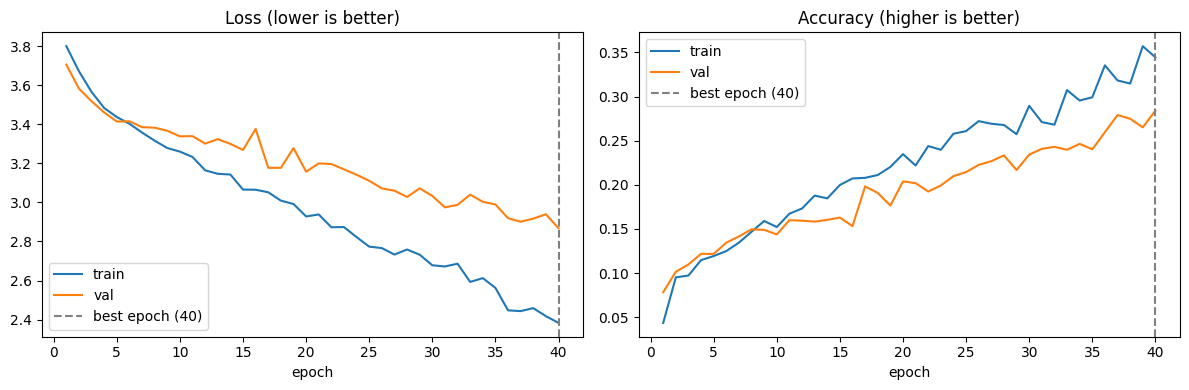

In [7]:
h = pd.DataFrame({k: v for k, v in hist.items() if k != "best_epoch"})
h.index = h.index + 1
best = hist["best_epoch"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "acc"]):
    ax.plot(h.index, h[f"train_{metric}"], label="train")
    ax.plot(h.index, h[f"val_{metric}"], label="val")
    ax.axvline(best, color="gray", linestyle="--", label=f"best epoch ({best})")
    ax.set_xlabel("epoch")
    ax.set_title({"loss": "Loss (lower is better)", "acc": "Accuracy (higher is better)"}[metric])
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Results

In [8]:
row = h.loc[best]
results = pd.Series({
    "best epoch": best,
    "epochs run": len(h),
    "train accuracy": f"{row.train_acc:.1%}",
    "val accuracy": f"{row.val_acc:.1%}",
    "random guessing": f"{1 / len(classes):.1%}",
    "training time (s)": round(end_time - start_time),
})
results

,0
best epoch,40
epochs run,40
train accuracy,34.4%
val accuracy,28.4%
random guessing,2.1%
training time (s),1096


**Findings**

- **Val accuracy 28.4%** after 40 epochs, about 13× random guessing (2.1%). The CNN learned real texture patterns from only 40 images per class.
- **Still improving at epoch 40.** The best epoch was the last one, so early stopping never triggered. More epochs would add a few points, but learning from scratch is slow (~18 min on a T4 GPU).
- **Start of overfitting.** Train accuracy 34.4% vs val 28.4%, and the gap between train and val loss keeps widening after ~epoch 7.
- **The LR scheduler helped.** Val loss stalled, so the learning rate was halved after epoch 35; val accuracy rose from 24% to 28% in the next few epochs.
- **Conclusion:** 40 images per class isn't enough to learn good filters from scratch. The next step reuses filters already learned on ImageNet (transfer learning).

**Next:** step 5, a pretrained ResNet18 trained with the same loop.